# 06 · Site figures

Two website deliverables from notebook 02's saved results (`data/analysis/`; nothing is refit):

1. **Card selection**: which tweaks go on the site, by rules fixed before looking at the
   picks, with the checks behind each.
2. **Static figure**: Parry's event study, `figures/site/spirometry_parry.png` (1600×1200) + PDF.
3. **Data export** for the interactive chart: `figures/site/spirometry_cards.json`.

The helpers are in `src/spirometry/site_figures.py`. Sections 1 and 2 need only the saved
tables. Section 3 also opens `data/runs/runs.duckdb` read-only, for the raw per-week counts
behind each event-study cell.

**Horizon.** Weeks 0–3 after the release is the primary horizon (PLAN.md decision log,
2026-10-09: "Weeks 0–3 is the primary horizon for every estimate in field guide v2; all
weeks is secondary"). Every headline number below is the weeks 0–3 fit (`did_h3`). The
event-study cells are fit over all weeks, as in notebook 02 (weeks binned at −6 and 8).

**Error bars.** Two kinds appear here. The weekly event-study bars, and the intervals in the JSON export, are the clustered-by-run ones from notebook 02: sampling error only. The placebo check (SPIROMETRY.md, “Placebo calibration of the DiD errors”) found those too narrow, by 4.10× at weeks 0–3 for first-patch cards and 2.67× for the second patch. The weeks 0–3 band in the Parry figure, and the headline intervals the website draws, are widened by that factor. After widening, Parry, Leading Strike and Untouchable stay well clear of zero (calibrated z ≈ 4–5); Debilitate sits at the edge (z ≈ 2).

In [1]:
import json
import os
import pathlib

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd()
if not (ROOT / "reference").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)

from spirometry import did, site_figures as sf

REF = ROOT / "reference"
DB = ROOT / "data" / "runs" / "runs.duckdb"
OUT = ROOT / "figures" / "site"
OUT.mkdir(parents=True, exist_ok=True)

saved = sf.load_saved(ROOT / "data" / "analysis")
TW = pd.read_csv(REF / "tweak_sizes.csv", dtype=str, keep_default_na=False).set_index("card_patch_id")
for c in ["log_ratio", "upgraded_log_ratio", "direction"]:
    TW[c] = pd.to_numeric(TW[c], errors="coerce")
BUILDS = pd.read_csv(REF / "builds.csv", dtype=str, keep_default_na=False).set_index("build_id")
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 80)

## 1. Card selection

Candidates proposed: Parry, Debilitate and Corrosive Wave (first patch), and Leading Strike.
For each: the weeks 0–3 and all-weeks β with 95% CI (points), the pre-trend screen from
notebook 02 (χ² of the before-build cells, p, weekly slope; a screen, not a test to report),
the offer-rate z's and flags, and every weeks 0–3 check that moves β by more than 2 se or
flips its sign.

In [2]:
CANDIDATES = ["PARRY@v0.103.2/patch", "DEBILITATE@v0.103.2/patch",
              "CORROSIVE_WAVE@v0.103.2/patch", "LEADING_STRIKE@v0.103.2/patch"]
rep = sf.selection_report(saved, CANDIDATES)
display(rep.T)

card_patch_id,PARRY@v0.103.2/patch,DEBILITATE@v0.103.2/patch,CORROSIVE_WAVE@v0.103.2/patch,LEADING_STRIKE@v0.103.2/patch
patch,first,first,first,first
beta_h3_pts,14.125465,6.063853,-15.316629,9.111715
ci_h3,+12.68 .. +15.57,+4.59 .. +7.54,-17.54 .. -13.09,+8.21 .. +10.01
beta_all_pts,14.531074,5.666725,-15.847239,9.954272
ci_all,+13.24 .. +15.82,+4.36 .. +6.98,-17.85 .. -13.85,+9.15 .. +10.76
pre_chi2,6.829998,5.157851,13.682859,5.370722
pre_p,0.145149,0.271481,0.008379,0.251329
pre_slope_pts,0.483986,-0.439158,1.04076,-0.53248
pre_slope_se_pts,0.663776,0.748241,1.289571,0.463045
z_spread,2.46552,0.610393,-1.471694,0.210189


### The nerf: replacing Corrosive Wave

Corrosive Wave fails the pre-trend screen (χ² 13.7 on 4 weeks, p = 0.008; one high week, slope
+1.0 ± 1.3 pts a week) and moves −2.7 se in the tagged-only fit. It is replaced by the
cleanest first-patch nerf, by a rule fixed before running it (Phil, 2026-10-27):
first-patch, solo-estimable, a nerf (not mixed), |β_h3| > 2 se, pre-trend p > 0.05, no
offer-rate flag (`flag` or `flag_rarity`), no sign flip in any weeks 0–3 check; the
largest |β_h3|. If nothing passed, Corrosive Wave would stay with a note.

In [3]:
NERF, nerf_steps = sf.pick_nerf(saved)
display(nerf_steps)
print("pick:", NERF)

,filter,n,cards
0,"first-patch, solo-estimable",26,"ANTICIPATE, CORROSIVE_WAVE, FLICK_FLACK, GRAND_FINALE, LEADING_STRIKE, MEMEN..."
1,nerf (not mixed),5,"ANTICIPATE, CORROSIVE_WAVE, FLICK_FLACK, PINPOINT, UNTOUCHABLE"
2,|β| > 2 se (weeks 0–3),5,"ANTICIPATE, CORROSIVE_WAVE, FLICK_FLACK, PINPOINT, UNTOUCHABLE"
3,pre-trend p > 0.05,4,"ANTICIPATE, FLICK_FLACK, PINPOINT, UNTOUCHABLE"
4,no offer-rate flag,4,"ANTICIPATE, FLICK_FLACK, PINPOINT, UNTOUCHABLE"
5,no sign flip in a weeks 0–3 check,4,"ANTICIPATE, FLICK_FLACK, PINPOINT, UNTOUCHABLE"


pick: UNTOUCHABLE@v0.103.2/patch


### The contrast card: a second-patch null

The first rule (second-patch, solo-estimable, |β_h3| < 2 se, no offer-rate flag; most
treated offers) picked **Crescent Spear** (−0.40 pts, 95% CI −1.53 to +0.73, weeks 0–3). It
was dropped: it is clearly nonzero at all weeks (+1.58 ± 0.52), moves +2.3 se when v0.103.2
is pooled into the before block, and its anticipation check shows a post-beta gap on the same
side as the main effect and larger (+1.9 ± 0.5), so players may have reacted to the beta
patch notes before the release.

The stricter rule (fixed 2026-10-27): second-patch, solo-estimable, no offer-rate flag, and
|β| < 2 se at weeks 0–3, at all weeks **and** with the pooled before block, and no
anticipation gap beyond 2 se where that check is informative. Then, for consistency with
the nerf rule (not a new criterion; Phil, 2026-10-27): pre-trend p > 0.05 and no weeks 0–3
check (the before-block variants included) moving it by more than 2 se. The most treated
offers (weeks 0–3) wins.

In [4]:
NULL, null_steps = sf.pick_null(saved)
display(null_steps)
print("pick:", NULL)

,filter,n,cards
0,"second-patch, solo-estimable",17,"BULWARK, CRESCENT_SPEAR, FURNACE, PATTER, REFLECT, ROYALTIES, DEATH_MARCH, D..."
1,no offer-rate flag,16,"BULWARK, CRESCENT_SPEAR, FURNACE, REFLECT, ROYALTIES, DEATH_MARCH, DEBILITAT..."
2,"|β| < 2 se, weeks 0–3",9,"CRESCENT_SPEAR, FURNACE, ROYALTIES, DEATH_MARCH, THE_SCYTHE, HYPERBEAM, SYNT..."
3,"|β| < 2 se, all weeks",5,"ROYALTIES, THE_SCYTHE, HYPERBEAM, JUGGERNAUT, UNTOUCHABLE"
4,"|β| < 2 se, pooled before block",5,"ROYALTIES, THE_SCYTHE, HYPERBEAM, JUGGERNAUT, UNTOUCHABLE"
5,no anticipation gap > 2 se (where informative),5,"ROYALTIES, THE_SCYTHE, HYPERBEAM, JUGGERNAUT, UNTOUCHABLE"
6,pre-trend p > 0.05,2,"ROYALTIES, THE_SCYTHE"
7,no weeks 0–3 check moves it > 2 se,2,"ROYALTIES, THE_SCYTHE"


pick: THE_SCYTHE@v0.107.1/patch


In [5]:
SELECTED = ["PARRY@v0.103.2/patch", "DEBILITATE@v0.103.2/patch", NERF,
            "LEADING_STRIKE@v0.103.2/patch"] + ([NULL] if NULL else [])
display(sf.selection_report(saved, SELECTED).T)
PATCH_SUMMARY = sf.patch_summary(saved)
PATCH_SUMMARY

card_patch_id,PARRY@v0.103.2/patch,DEBILITATE@v0.103.2/patch,UNTOUCHABLE@v0.103.2/patch,LEADING_STRIKE@v0.103.2/patch,THE_SCYTHE@v0.107.1/patch
patch,first,first,first,first,second
beta_h3_pts,14.125465,6.063853,-8.137832,9.111715,-1.382643
ci_h3,+12.68 .. +15.57,+4.59 .. +7.54,-9.05 .. -7.22,+8.21 .. +10.01,-3.84 .. +1.08
beta_all_pts,14.531074,5.666725,-9.379302,9.954272,0.395535
ci_all,+13.24 .. +15.82,+4.36 .. +6.98,-10.20 .. -8.56,+9.15 .. +10.76,-1.80 .. +2.59
pre_chi2,6.829998,5.157851,3.787876,5.370722,0.243926
pre_p,0.145149,0.271481,0.435474,0.251329,0.885181
pre_slope_pts,0.483986,-0.439158,1.02316,-0.53248,1.690912
pre_slope_se_pts,0.663776,0.748241,0.531275,0.463045,3.663353
z_spread,2.46552,0.610393,0.334019,0.210189,2.250625


{'first': {'median_abs_beta_pts': 4.4, 'n_clear': 13, 'n': 26},
 'second': {'median_abs_beta_pts': 1.95, 'n_clear': 2, 'n': 17}}

### Selection record (2026-10-27)

Run on the final tables' saved fits (`did_h3`, `did_main`, `did_h3_*`, `event_studies`,
`offer_rate`, `second_patch_checks_h3`, `anticipation_main`).

**Kept:**
- **Parry** (first patch, buff): +14.13 pts (12.68 to 15.57), weeks 0–3. Pre-trend χ² 6.83, p 0.15,
  slope +0.48 ± 0.66. The offer rate isn't flagged, but it's close: z_binom 2.90, 2.96
  against same-rarity cards (both z's must pass 3). Picked-screens-only moves it +3.8 se. No
  sign flips.
- **Debilitate** (first patch, buff): +6.06 pts (4.59 to 7.54). Pre-trend p 0.27. No offer flag.
  Picked-screens-only +2.4 se. No flips.
- **Leading Strike** (first patch, **rework**: 7 damage + 1 Shiv → 3 damage + 2 Shivs,
  11 → 11 total; the patch notes call it "Buffed"): +9.11 pts (8.21 to 10.01). Pre-trend p 0.25.
  No offer flag. Tagged-only +4.5 se, picked-screens-only +3.7 se, both the same sign.

Picked-screens-only moves 30% of all tweaks by more than 2 se (slope of check on main 1.13;
SPIROMETRY.md), so those moves are the check's, not specific to these cards.

**Nerf rule:** 26 → 5 nerfs (not mixed) → 5 with |β| > 2 se → 4 with pre-trend p > 0.05
(Corrosive Wave out) → 4 without an offer-rate flag → 4 without a sign flip. Pick:
**Untouchable** v0.103.2 (Block 9 → 6), −8.14 pts (−9.05 to −7.22). Pre-trend p 0.44, but
slope +1.02 ± 0.53 a week (1.9 se, rising; SPIROMETRY.md lists it among the weaker drifts).
Tagged-only moves it −4.0 se (same sign). Corrosive Wave is not used, so no Corrosive Wave
note.

**Contrast rule (stricter):**
- Filter counts: 17 second-patch tweaks.
  - 16 have no offer-rate flag (Patter out).
  - 9 have |β| < 2 se at weeks 0–3.
  - 5 also at all weeks (Crescent Spear, Furnace, Death March, Synthesis out).
  - 5 also with the pooled before block.
  - 5 with no informative anticipation gap. Only Hyperbeam's check is informative; its gap
    is −0.6 ± 0.8.
- That left Royalties, The Scythe, Hyperbeam, Juggernaut and Untouchable v0.107.1, and the
  rule as it stood picked **Juggernaut** (damage 5 → 6, buff; 7,186 treated offers), at
  −2.00 pts (−4.19 to +0.18) for weeks 0–3. Dropped for the nerf rule's filters:
  - pre-trend χ² 8.96 on 2 weeks, p 0.011;
  - tagged-only moves it −5.3 se.

  It also had an offer-rate z_spread of −3.09, though z_binom was −2.22, so no flag.
- With the nerf rule's two filters added:
  - Pre-trend p > 0.05: 2 of 5 pass. Out: Hyperbeam (p 0.014), Juggernaut (0.011) and
    Untouchable v0.107.1 (0.005).
  - No check moving it more than 2 se: 2 of 2 pass.
- Pick: **The Scythe** (Necrobinder; `vars.Increase` 3 → 4, upgraded 4 → 5; the v0.107.0
  patch notes call it "damage", v0.110.0's notes call the same number "damage scaling").
  It is a buff, with 5,428 treated offers.
  - Weeks 0–3: −1.38 pts (−3.84 to +1.08). All weeks: +0.40 (−1.80 to +2.59).
  - Pre-trend: χ² 0.24 on 2 weeks, p 0.89.
  - Largest check shift: +0.7 se (pooled before block).
  - Offer rate: z_spread +2.25, z_binom +1.78, no flag.
  - The only other survivor, Royalties, is upgrade-only, with 137 treated offers.

**"The second patch was weaker"** is made with the median |β| comparison at weeks 0–3, not
with the contrast card: 4.40 pts (13 of 26 tweaks with calibrated |z| > 2) in the first patch,
1.95 pts (2 of 17) in the second (`PATCH_SUMMARY`; z divided by `sf.PLACEBO_FACTORS_H3`, as
SPIROMETRY.md's calibrated counts). The selection rules above stay on clustered SEs.

## 2. Static figure: Parry

Notebook 02's event study, Parry only, in percentage points. Cells with fewer than 100 treated
offers are hidden, as in notebook 02. Week −1 of the old build is the reference (0 by
definition). The coral band is the weeks 0–3 average, 95% interval widened by the first-patch
placebo factor (`sf.PLACEBO_FACTORS_H3`). Only the saved event study is needed
here. The caption leaves the CI out.

The change is from the patch notes (`reference/patch_notes_cards.csv`). Parry's Block when you
play Sovereign Blade went 6(9) → 8(11) in beta v0.100.0 and 8(11) → 10(14) in v0.101.0; both
reached stable in v0.103.2. It is Block, not Vigor.

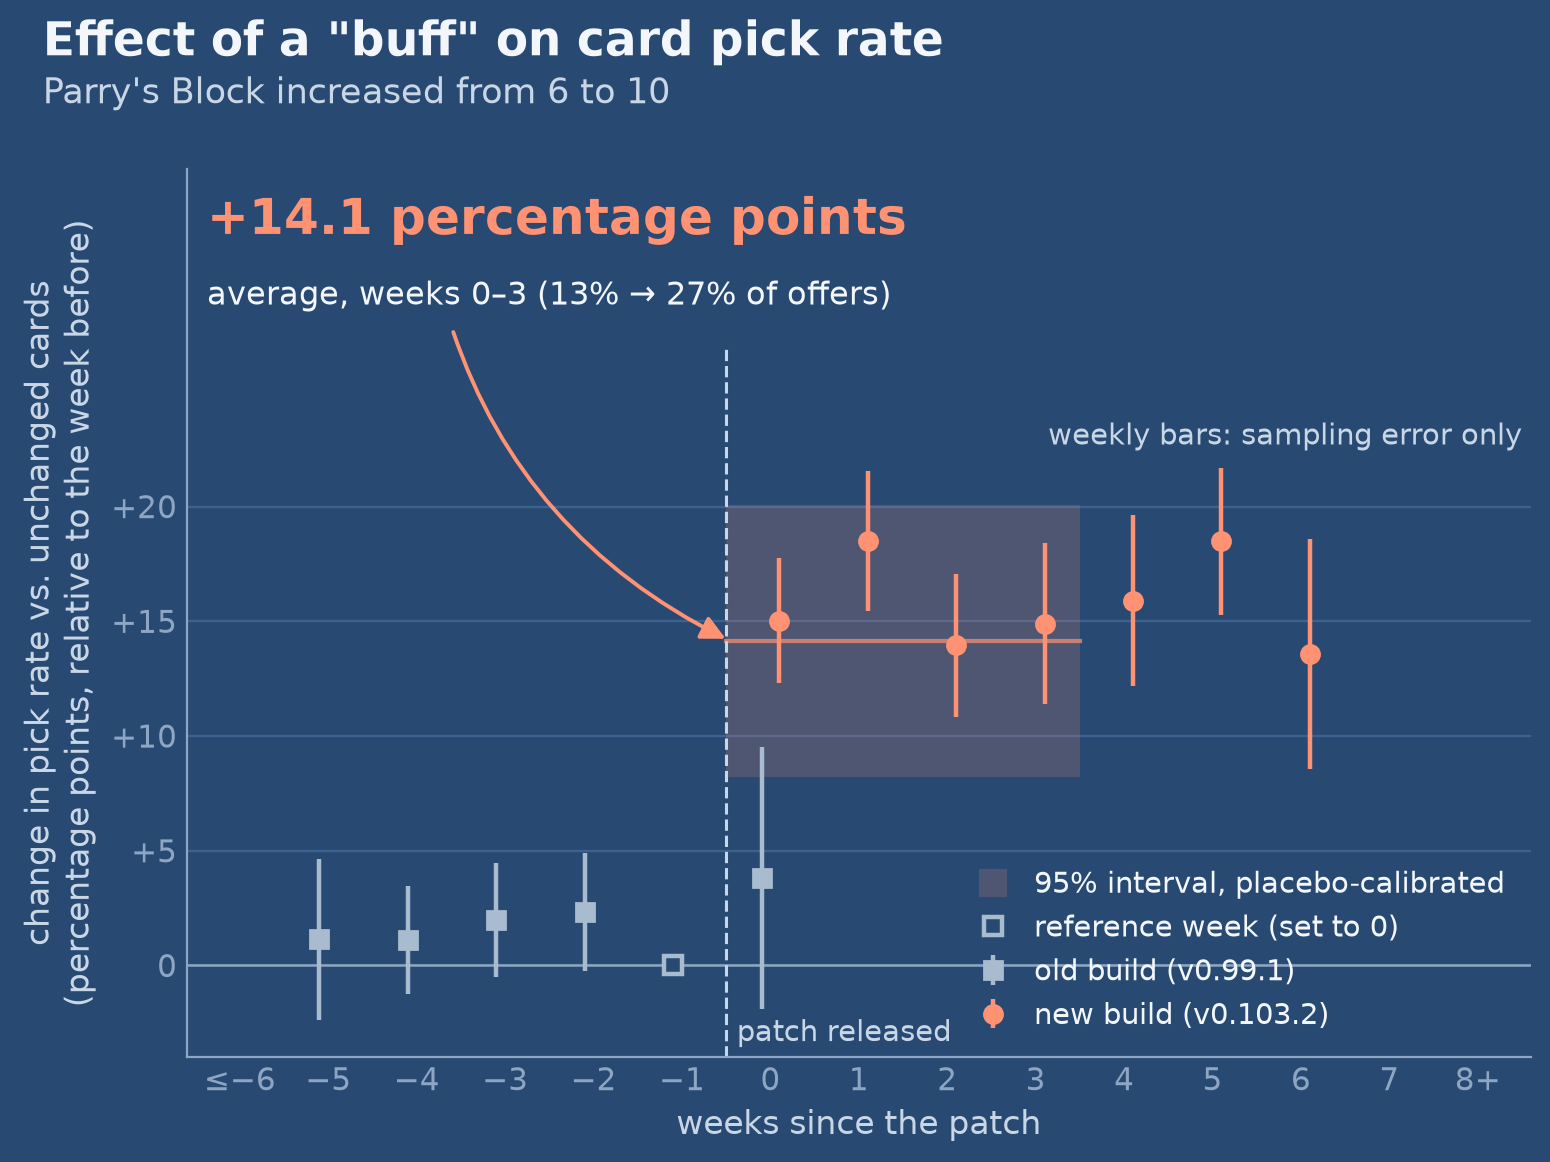

After a patch raised Parry's Block from 6 to 10, players picked it 14 percentage points more often (13% → 27% of offers) than comparable unchanged cards over the first four weeks, with no clear drift before the patch.


In [6]:
PARRY = "PARRY@v0.103.2/patch"
parry_head = sf.card_entry(saved, PARRY, None, change_text="", tweaks=TW, builds=BUILDS,
                           name="Parry")
with plt.rc_context(sf.SITE_STYLE):
    fig = sf.plot_event_study_site(
        sf.es_cells(saved["es"], PARRY), parry_head,
        title='Effect of a "buff" on card pick rate',
        change_label="Parry's Block increased from 6 to 10")
    fig.savefig(OUT / "spirometry_parry.png", dpi=200)
    fig.savefig(OUT / "spirometry_parry.pdf")
plt.show()
h = parry_head["headline"]
CAPTION = (f"After a patch raised Parry's Block from 6 to 10, players picked it "
           f"{h['beta_pts']:.0f} percentage points more often ({h['treated_rate_before']:.0%} → "
           f"{h['treated_rate_after']:.0%} of offers) than comparable unchanged cards over the "
           f"first four weeks, with no clear drift before the patch.")
print(CAPTION)

## 3. Data export for the interactive chart

One entry per selected card. The headline is the weeks 0–3 fit. `weeks` holds the event-study
cells with at least 100 treated offers: `coef_pts` / `se_pts` from the saved event study, and
`offers`, `picks`, `pick_rate`, `control_pick_rate` counted raw from the same window data,
with the same subset and week bins that `did.fit_event_study` uses (`sf.weekly_cells`
raises if its treated offers don't match the saved event study's). The reference cell
(week −1, old build) has `coef_pts` 0 and `se_pts` null. The headline CIs stay raw: the site
widens them at draw time by the same factors (`CAL` in `index.html`). `patch_summary`'s
`n_clear` is the calibrated count.

`change_text` is from the patch notes (`reference/patch_notes_cards.csv`); the assert checks
it against `tweak_sizes.csv`'s base numbers.

In [7]:
NAMES = {"PARRY": "Parry", "DEBILITATE": "Debilitate", "LEADING_STRIKE": "Leading Strike",
         "UNTOUCHABLE": "Untouchable", "JUGGERNAUT": "Juggernaut",
         "CORROSIVE_WAVE": "Corrosive Wave", "THE_SCYTHE": "The Scythe"}
CHANGE_TEXT = {      # patch notes, base(upgraded), net over the betas that reached stable
    "PARRY@v0.103.2/patch": "Block 6 → 10 when you play Sovereign Blade (upgraded 9 → 14)",
    "DEBILITATE@v0.103.2/patch": "Damage 7 → 10 (upgraded 9 → 12)",
    "LEADING_STRIKE@v0.103.2/patch": "Damage 7 → 3, Shivs 1 → 2 (11 total damage either way)",
    "UNTOUCHABLE@v0.103.2/patch": "Block 9 → 6 (upgraded 12 → 8)",
    "CORROSIVE_WAVE@v0.103.2/patch": "Poison 3 → 2 (upgraded 4 → 3)",
    "JUGGERNAUT@v0.107.1/patch": "Damage 5 → 6 (upgraded 7 → 8)",
    "THE_SCYTHE@v0.107.1/patch": "Damage scaling 3 → 4 (upgraded 4 → 5)",
}
KIND = {"LEADING_STRIKE@v0.103.2/patch": "rework"}
NOTES = {NULL: "No clear change: the effect is within noise at every horizon."} if NULL else {}
if "CORROSIVE_WAVE@v0.103.2/patch" in SELECTED:
    NOTES["CORROSIVE_WAVE@v0.103.2/patch"] = ("One pre-patch week was unusually high; the "
                                              "overall pre-patch trend is flat.")
for cpid in SELECTED:
    t = TW.loc[cpid]
    assert CHANGE_TEXT.get(cpid), f"{cpid}: write its change_text from the patch notes"
    assert f"{t.old} → {t.new}" in CHANGE_TEXT[cpid], (cpid, t.old, t.new)

In [8]:
con = duckdb.connect(str(DB), read_only=True)
con.execute("SET enable_progress_bar = false")
cards, CELLS = [], {}
for (color, before, after), g in TW.loc[SELECTED].groupby(
        ["color", "before_builds", "after_builds"], sort=False):
    df = did.load_block_data(con, color, before, after, ref=REF)      # one window at a time
    for cpid in g.index:
        upg = True if TW.loc[cpid, "upgrade_only"] == "yes" else None
        CELLS[cpid] = sf.weekly_cells(df, cpid, saved["es"], upgraded=upg, ref=REF)
    del df
con.close()

for cpid in SELECTED:
    cards.append(sf.card_entry(saved, cpid, CELLS[cpid], change_text=CHANGE_TEXT[cpid],
                               tweaks=TW, builds=BUILDS, name=NAMES[TW.loc[cpid, "card_id"]],
                               kind=KIND.get(cpid), note=NOTES.get(cpid)))
export = {
    "horizon": sf.HORIZON_LABEL,
    "min_treated_offers": sf.MIN_OFFERS,
    "weeks_note": ("week = whole weeks since the new build's release; week −6 includes "
                   "earlier weeks and week 8 later ones; week −1 of the old build is the "
                   "reference (coef 0). Weekly error bars are clustered by run: sampling "
                   "error only. Headline CIs are raw too; the site widens them by the "
                   "placebo factors at draw time. n_clear is calibrated."),
    "patch_summary": PATCH_SUMMARY,
    "cards": cards,
}
path = OUT / "spirometry_cards.json"
path.write_text(json.dumps(export, ensure_ascii=False, separators=(",", ":")))
print(f"{path.relative_to(ROOT)}: {path.stat().st_size / 1024:.1f} KB, {len(cards)} cards")
assert path.stat().st_size < 100 * 1024
for c in cards:
    h = c["headline"]
    print(f"{c['name']:15s} {c['kind']:7s} {h['beta_pts']:+.2f} ({h['ci_lo_pts']:+.2f} to {h['ci_hi_pts']:+.2f}, raw)")

figures/site/spirometry_cards.json: 11.5 KB, 5 cards
Parry           buff    +14.13 (+12.68 to +15.57, raw)
Debilitate      buff    +6.06 (+4.59 to +7.54, raw)
Untouchable     nerf    -8.14 (-9.05 to -7.22, raw)
Leading Strike  rework  +9.11 (+8.21 to +10.01, raw)
The Scythe      buff    -1.38 (-3.84 to +1.08, raw)


In [9]:
# Raw cells against the fit: the raw gap change should track coef roughly (the fit adds
# fixed effects), and the before-block weeks should hover near the reference.
for cpid in SELECTED:
    c = CELLS[cpid]
    c = c[c.offers >= sf.MIN_OFFERS].assign(raw_gap=lambda d: d.pick_rate - d.control_pick_rate)
    ref_gap = c.loc[c.is_ref, "raw_gap"].squeeze() if c.is_ref.any() else np.nan
    print(cpid)
    display(c.assign(raw_gap_vs_ref_pts=100 * (c.raw_gap - ref_gap), coef_pts=100 * c.coef)
             [["week", "block", "offers", "picks", "pick_rate", "control_pick_rate",
               "raw_gap_vs_ref_pts", "coef_pts"]].round(4))

PARRY@v0.103.2/patch


,week,block,offers,picks,pick_rate,control_pick_rate,raw_gap_vs_ref_pts,coef_pts
0,-5,before,503,59,0.1173,0.2693,1.0772,1.1488
1,-4,before,2277,282,0.1238,0.2748,1.1813,1.1069
2,-3,before,1960,264,0.1347,0.2789,1.8574,1.9833
3,-2,before,1617,233,0.1441,0.2806,2.6214,2.3228
4,-1,before,1377,163,0.1184,0.2811,0.0000,0.0000
5,0,before,190,29,0.1526,0.2743,4.1023,3.8277
14,0,after,2320,597,0.2573,0.2681,15.1955,15.0325
15,1,after,1572,462,0.2939,0.2741,18.2506,18.5124
16,2,after,1306,327,0.2504,0.2750,13.8127,13.9468
17,3,after,1007,261,0.2592,0.2706,15.1301,14.8984


DEBILITATE@v0.103.2/patch


,week,block,offers,picks,pick_rate,control_pick_rate,raw_gap_vs_ref_pts,coef_pts
0,-5,before,511,92,0.1800,0.2405,-0.7501,-1.2329
1,-4,before,2319,496,0.2139,0.2430,2.3900,2.1758
2,-3,before,1775,305,0.1718,0.2433,-1.8511,-2.1049
3,-2,before,1702,319,0.1874,0.2410,-0.0596,-0.1988
4,-1,before,1380,256,0.1855,0.2385,0.0000,0.0000
5,0,before,181,34,0.1878,0.2417,-0.0806,-0.3110
12,0,after,1764,461,0.2613,0.2440,7.0292,6.9921
13,1,after,1395,370,0.2652,0.2499,6.8311,6.7772
14,2,after,1127,267,0.2369,0.2460,4.3891,4.8280
15,3,after,941,237,0.2519,0.2531,5.1730,5.2352


UNTOUCHABLE@v0.103.2/patch


,week,block,offers,picks,pick_rate,control_pick_rate,raw_gap_vs_ref_pts,coef_pts
0,-5,before,1363,385,0.2825,0.2501,-1.8077,-1.8503
1,-4,before,7291,2173,0.2980,0.2555,-0.7995,-0.7698
2,-3,before,5859,1776,0.3031,0.2551,-0.2427,0.0463
3,-2,before,5143,1615,0.3140,0.2519,1.1665,1.2917
4,-1,before,4380,1349,0.3080,0.2575,0.0000,0.0000
5,0,before,674,237,0.3516,0.2574,4.3742,4.3018
14,0,after,6357,1579,0.2484,0.2663,-6.8429,-6.7131
15,1,after,4518,1110,0.2457,0.2717,-7.6489,-7.6058
16,2,after,3746,855,0.2282,0.2684,-9.0692,-8.9320
17,3,after,3532,793,0.2245,0.2786,-10.4596,-10.5019


LEADING_STRIKE@v0.103.2/patch


,week,block,offers,picks,pick_rate,control_pick_rate,raw_gap_vs_ref_pts,coef_pts
0,-5,before,1310,258,0.1969,0.2501,2.3021,2.5562
1,-4,before,7380,1354,0.1835,0.2555,0.4053,0.6539
2,-3,before,5833,991,0.1699,0.2551,-0.9038,-0.7220
3,-2,before,5229,947,0.1811,0.2519,0.5369,0.5598
4,-1,before,4499,816,0.1814,0.2575,0.0000,0.0000
5,0,before,706,122,0.1728,0.2574,-0.8468,-0.6417
14,0,after,6492,1729,0.2663,0.2663,7.6129,7.9210
15,1,after,4548,1285,0.2825,0.2717,8.6986,8.6306
16,2,after,3748,1169,0.3119,0.2684,11.9581,12.0120
17,3,after,3658,1102,0.3013,0.2786,9.8760,9.9600


THE_SCYTHE@v0.107.1/patch


,week,block,offers,picks,pick_rate,control_pick_rate,raw_gap_vs_ref_pts,coef_pts
0,-3,before,491,132,0.2688,0.2637,-1.5184,-1.2365
1,-2,before,701,201,0.2867,0.2640,0.2415,0.4544
2,-1,before,594,167,0.2811,0.2608,0.0000,0.0000
3,0,before,107,29,0.2710,0.2611,-1.0383,-0.4446
10,0,after,1051,267,0.2540,0.2630,-2.9264,-2.2625
11,1,after,1066,262,0.2458,0.2612,-3.5687,-2.8995
12,2,after,738,200,0.2710,0.2650,-1.4338,-1.0038
13,3,after,668,192,0.2874,0.2629,0.4261,0.6899
14,4,after,578,170,0.2941,0.2673,0.6473,1.0389
15,5,after,542,173,0.3192,0.2643,3.4623,3.9977
